In [1]:
import argparse
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as tck
import numpy as np

plt.rcParams["font.size"] = 8

def load_curve(run_dir: Path, client: str, eval_name: str, round=-1):
    """Load pre/post metrics for one run directory."""
    rounds = sorted(
        (run_dir / "eval_rounds").glob("round_*"),
        key=lambda p: int(p.name.split("_")[1]),
    )
    rpath = rounds[round]
    rid = int(rpath.name.split("_")[1])
    if client == 'server_post_agg':
        fpath = rpath / f"{client}" / "TOFU_EVAL.json"
    else:
        fpath = rpath / f"{client}_{"post_train"}" / "TOFU_EVAL.json"
    if not fpath.exists():
        print(fpath)
    payload = json.loads(fpath.read_text())
    xs = rid
    ys = payload[eval_name]["agg_value"]
    return xs, ys

In [62]:
plt.rcParams['text.usetex'] = True
size = (4, 1.2)

method = "fedperm_only"
retain_split = "retain90"
# fl_method = "FedAvg"
fl_method = "FedProx"
ul_method = "SimNPO"
# ul_method = "GradAscent"
epoch = 0
ce0 = 1
alpha = 1
# model = "Qwen2.5-1.5B"
models = ["Llama-3.2-1B", "Qwen2.5-1.5B"]

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


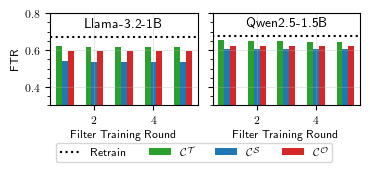

In [63]:
source_client = "client0"
target_client = "client1"
other_client = "client2"
# eval_name = "ra_Q_A_Prob"
# eval_name = "model_utility"
eval_name = "forget_truth_ratio"
# eval_name = "forget_utility"

width=0.2

# method_root = Path("saves") / args.method
method_root = Path("saves/TOFU") / method

fig, ax = plt.subplots(1, 2, figsize=size, sharex=False, sharey=True)

for i, model in enumerate(models):

    xa1 = [-1,1,2,3,6]
    ya1 = []
    xa2 = [-1,1,2,3,6]
    ya2 = []
    xa_t = []
    ya_t = []
    xa_s = []
    ya_s = []
    xa_o = []
    ya_o = []
    for fr in range(1,6):
        runs = {
            "Finetune": method_root / f"full_{fl_method}_{model}-Instruct-lora_{retain_split}",
            "Retain": method_root / f"retain_{fl_method}_{model}-Instruct-lora_{retain_split}",
        }
        for name, path in runs.items():
            if not path.exists():
                print(path)
                continue
            if name == "Finetune":
                xs, ys = load_curve(path, client=target_client, eval_name=eval_name, round=15)
                # xa1.append(fr)
                ya1.append(ys)
            elif name == "Retain":
                xs, ys = load_curve(path, client=target_client, eval_name=eval_name, round=15)
                # xa2.append(fr)
                ya2.append(ys)

    for fr in range(1,6):
        runs = method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_filter{fr}_CE1_Alpha1"

        if not path.exists():
            print(path)
            continue
        xs, ys = load_curve(runs, client=target_client, eval_name=eval_name, round=epoch)
        xa_t.append(fr)
        ya_t.append(ys)

        xs, ys = load_curve(runs, client=source_client, eval_name=eval_name, round=epoch)
        xa_s.append(fr)
        ya_s.append(ys)

        xs, ys = load_curve(runs, client=other_client, eval_name=eval_name, round=epoch)
        xa_o.append(fr)
        ya_o.append(ys)


    colors = {
        "source": "#1f77b4",
        "target": "#2ca02c",
        "other": "#d62728"
    }

    xa1 = np.array(xa1)
    ya1 = np.array(ya1)
    xa2 = np.array(xa2)
    ya2 = np.array(ya2)
    xa_t = np.array(xa_t)
    ya_t = np.array(ya_t)
    xa_s = np.array(xa_s)
    ya_s = np.array(ya_s)
    xa_o = np.array(xa_o)
    ya_o = np.array(ya_o)

    ax[i].plot(
        xa2,
        ya2,
        label=f"Retrain",
        color="#000000",
        linestyle=":"
    )

    # ax[i].plot(
    #     xa1,
    #     ya1,
    #     label=f"Finetune",
    #     color="#000000",
    #     linestyle=":"
    # )

    ax[i].bar(
        xa_t-width,
        ya_t,
        width,
        label=r'$\mathcal{C}^\mathcal{T}$',
        color=colors.get("target")
    )

    ax[i].bar(
        xa_s,
        ya_s,
        width,
        label=r'$\mathcal{C}^\mathcal{S}$',
        color=colors.get("source")
    )

    ax[i].bar(
        xa_o+width,
        ya_o,
        width,
        label=r'$\mathcal{C}^\mathcal{O}$',
        color=colors.get("other")
    )

    ax[i].yaxis.set_minor_locator(tck.AutoMinorLocator())
    ax[i].set_xlabel("Filter Training Round")
    ax[i].set_title(f"{model}", y=0.86, va="top")
    ax[i].set_xlim(xmin=0.5, xmax=5.5)
    ax[i].set_ylim(ymin=0.3, ymax=0.8)
    ax[i].grid(True, alpha=0.3)
ax[0].set_ylabel("FTR")
# ax.set_title(f"Model = {model}")
handles, labels = ax[0].get_legend_handles_labels()
if labels:
    lgd = ax[i].legend(loc='center left', bbox_to_anchor=(-1.1,-0.51), ncol=4)
# plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
out = f"client_{retain_split}_{fl_method}_{ul_method}_{model}_{eval_name}_ha.eps"
plt.savefig(out, dpi=200, bbox_extra_artists=(lgd,), bbox_inches='tight')
# print(f"Saved plot to {out}")
plt.show()

<>:129: SyntaxWarning: invalid escape sequence '\%'
<>:129: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_8397/565839075.py:129: SyntaxWarning: invalid escape sequence '\%'
  ax[0].set_ylabel("MU (\%)")
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


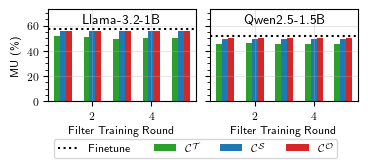

In [57]:
source_client = "client0"
target_client = "client1"
other_client = "client2"
# eval_name = "ra_Q_A_Prob"
eval_name = "model_utility"
# eval_name = "forget_truth_ratio"
# eval_name = "forget_utility"

width=0.2

# method_root = Path("saves") / args.method
method_root = Path("saves/TOFU") / method

fig, ax = plt.subplots(1, 2, figsize=size, sharex=False, sharey=True)

for i, model in enumerate(models):

    xa1 = [-1,1,2,3,6]
    ya1 = []
    xa2 = [-1,1,2,3,6]
    ya2 = []
    xa_t = []
    ya_t = []
    xa_s = []
    ya_s = []
    xa_o = []
    ya_o = []
    for fr in range(1,6):
        runs = {
            "Finetune": method_root / f"full_{fl_method}_{model}-Instruct-lora_{retain_split}",
            "Retain": method_root / f"retain_{fl_method}_{model}-Instruct-lora_{retain_split}",
        }
        for name, path in runs.items():
            if not path.exists():
                print(path)
                continue
            if name == "Finetune":
                xs, ys = load_curve(path, client=target_client, eval_name=eval_name, round=15)
                # xa1.append(fr)
                ya1.append(ys)
            elif name == "Retain":
                xs, ys = load_curve(path, client=target_client, eval_name=eval_name, round=15)
                # xa2.append(fr)
                ya2.append(ys)

    for fr in range(1,6):
        runs = method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_filter{fr}_CE1_Alpha1"

        if not path.exists():
            print(path)
            continue
        xs, ys = load_curve(runs, client=target_client, eval_name=eval_name, round=epoch)
        xa_t.append(fr)
        ya_t.append(ys)

        xs, ys = load_curve(runs, client=source_client, eval_name=eval_name, round=epoch)
        xa_s.append(fr)
        ya_s.append(ys)

        xs, ys = load_curve(runs, client=other_client, eval_name=eval_name, round=epoch)
        xa_o.append(fr)
        ya_o.append(ys)


    colors = {
        "source": "#1f77b4",
        "target": "#2ca02c",
        "other": "#d62728"
    }

    xa1 = np.array(xa1)
    ya1 = np.array(ya1)
    xa2 = np.array(xa2)
    ya2 = np.array(ya2)
    xa_t = np.array(xa_t)
    ya_t = np.array(ya_t)
    xa_s = np.array(xa_s)
    ya_s = np.array(ya_s)
    xa_o = np.array(xa_o)
    ya_o = np.array(ya_o)

    # ax[i].plot(
    #     xa2,
    #     100*ya2,
    #     label=f"Retain",
    #     color="#000000",
    #     linestyle="-.",
    #     linewidth=0.75
    # )

    ax[i].plot(
        xa1,
        100*ya1,
        label=f"Finetune",
        color="#000000",
        linestyle=":"
    )

    ax[i].bar(
        xa_t-width,
        100*ya_t,
        width,
        label=r'$\mathcal{C}^\mathcal{T}$',
        color=colors.get("target")
    )

    ax[i].bar(
        xa_s,
        100*ya_s,
        width,
        label=r'$\mathcal{C}^\mathcal{S}$',
        color=colors.get("source")
    )

    ax[i].bar(
        xa_o+width,
        100*ya_o,
        width,
        label=r'$\mathcal{C}^\mathcal{O}$',
        color=colors.get("other")
    )

    ax[i].yaxis.set_minor_locator(tck.AutoMinorLocator())
    ax[i].set_xlabel("Filter Training Round")
    ax[i].set_title(f"{model}", y=0.86, va="top")
    ax[i].set_xlim(xmin=0.5, xmax=5.5)
    ax[i].grid(True, alpha=0.3)
    ax[i].set_ylim(ymin=0, ymax=73)
ax[0].set_ylabel("MU (\%)")
# ax.set_title(f"Model = {model}")
handles, labels = ax[0].get_legend_handles_labels()
if labels:
    lgd = ax[i].legend(loc='center left', bbox_to_anchor=(-1.1,-0.51), ncol=4)
# plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
out = f"client_{retain_split}_{fl_method}_{ul_method}_{model}_{eval_name}_ha.eps"
plt.savefig(out, dpi=200, bbox_extra_artists=(lgd,), bbox_inches='tight')
# print(f"Saved plot to {out}")
plt.show()